# XGBoost y LightGBM: predicción de fuga de clientes

**Curso:** Machine Learning para la Toma de Decisiones · Universidad del Pacífico

**Objetivo:** entrenar y comparar XGBoost y LightGBM para identificar clientes con riesgo de abandonar el banco, priorizando el recall y el AUC.

## Paso 1: Importar librerías

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import xgboost as xgb
import lightgbm as lgb
import shap
from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, roc_curve, confusion_matrix, classification_report)

SEED = 42
warnings.filterwarnings("ignore", message=".*eval_set.*")
pd.set_option("display.float_format", "{:.3f}".format)

## Paso 2: Cargar los datos

In [3]:
df = pd.read_csv("/content/Churn_Modelling.csv")
df.head(3)

,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,1,15634602,Hargrave,619,France,Female,42,2,0.000,1,1,1,101348.880,1
1,2,15647311,Hill,608,Spain,Female,41,1,83807.860,1,0,1,112542.580,0
2,3,15619304,Onio,502,France,Female,42,8,159660.800,3,1,0,113931.570,1


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   RowNumber        10000 non-null  int64  
 1   CustomerId       10000 non-null  int64  
 2   Surname          10000 non-null  object 
 3   CreditScore      10000 non-null  int64  
 4   Geography        10000 non-null  object 
 5   Gender           10000 non-null  object 
 6   Age              10000 non-null  int64  
 7   Tenure           10000 non-null  int64  
 8   Balance          10000 non-null  float64
 9   NumOfProducts    10000 non-null  int64  
 10  HasCrCard        10000 non-null  int64  
 11  IsActiveMember   10000 non-null  int64  
 12  EstimatedSalary  10000 non-null  float64
 13  Exited           10000 non-null  int64  
dtypes: float64(2), int64(9), object(3)
memory usage: 1.1+ MB


Se eliminan los identificadores, ya que no aportan valor predictivo.

In [6]:
df = df.drop(columns=["RowNumber", "CustomerId", "Surname"])
df.isnull().sum()

,0
CreditScore,0
Geography,0
Gender,0
Age,0
Tenure,0
Balance,0
NumOfProducts,0
HasCrCard,0
IsActiveMember,0
EstimatedSalary,0


## Paso 3: Análisis exploratorio

In [7]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
CreditScore,10000.000,650.529,96.653,350.000,584.000,652.000,718.000,850.000
Age,10000.000,38.922,10.488,18.000,32.000,37.000,44.000,92.000
Tenure,10000.000,5.013,2.892,0.000,3.000,5.000,7.000,10.000
Balance,10000.000,76485.889,62397.405,0.000,0.000,97198.540,127644.240,250898.090
NumOfProducts,10000.000,1.530,0.582,1.000,1.000,1.000,2.000,4.000
HasCrCard,10000.000,0.706,0.456,0.000,0.000,1.000,1.000,1.000
IsActiveMember,10000.000,0.515,0.500,0.000,0.000,1.000,1.000,1.000
EstimatedSalary,10000.000,100090.240,57510.493,11.580,51002.110,100193.915,149388.247,199992.480
Exited,10000.000,0.204,0.403,0.000,0.000,0.000,0.000,1.000


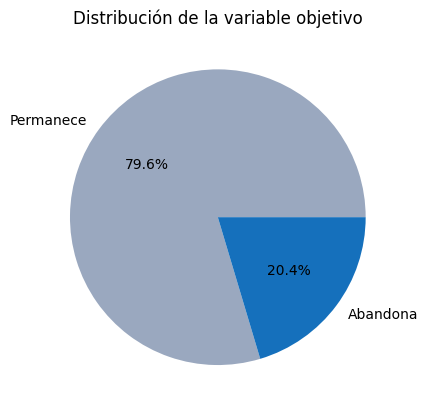

In [8]:
temp = df["Exited"].value_counts().rename(index={0: "Permanece", 1: "Abandona"})
plt.pie(temp.values, labels=temp.index, autopct="%1.1f%%", colors=["#9AA8BF", "#1570BC"])
plt.title("Distribución de la variable objetivo")
plt.show()

La clase positiva representa cerca del 20% de los casos. Por ello, el accuracy no basta para evaluar el modelo: se reportan también recall, F1 y AUC.

In [9]:
for col in ["Geography", "Gender", "IsActiveMember", "NumOfProducts"]:
    tabla = pd.DataFrame({
        "Frecuencia": df[col].value_counts(),
        "Porcentaje (%)": df[col].value_counts(normalize=True) * 100,
        "Tasa de fuga (%)": df.groupby(col)["Exited"].mean() * 100,
    })
    print(f"{col}\n{tabla.round(1)}\n")

Geography
           Frecuencia  Porcentaje (%)  Tasa de fuga (%)
Geography                                              
France           5014          50.100            16.200
Germany          2509          25.100            32.400
Spain            2477          24.800            16.700

Gender
        Frecuencia  Porcentaje (%)  Tasa de fuga (%)
Gender                                              
Female        4543          45.400            25.100
Male          5457          54.600            16.500

IsActiveMember
                Frecuencia  Porcentaje (%)  Tasa de fuga (%)
IsActiveMember                                              
0                     4849          48.500            26.900
1                     5151          51.500            14.300

NumOfProducts
               Frecuencia  Porcentaje (%)  Tasa de fuga (%)
NumOfProducts                                              
1                    5084          50.800            27.700
2                    4590          

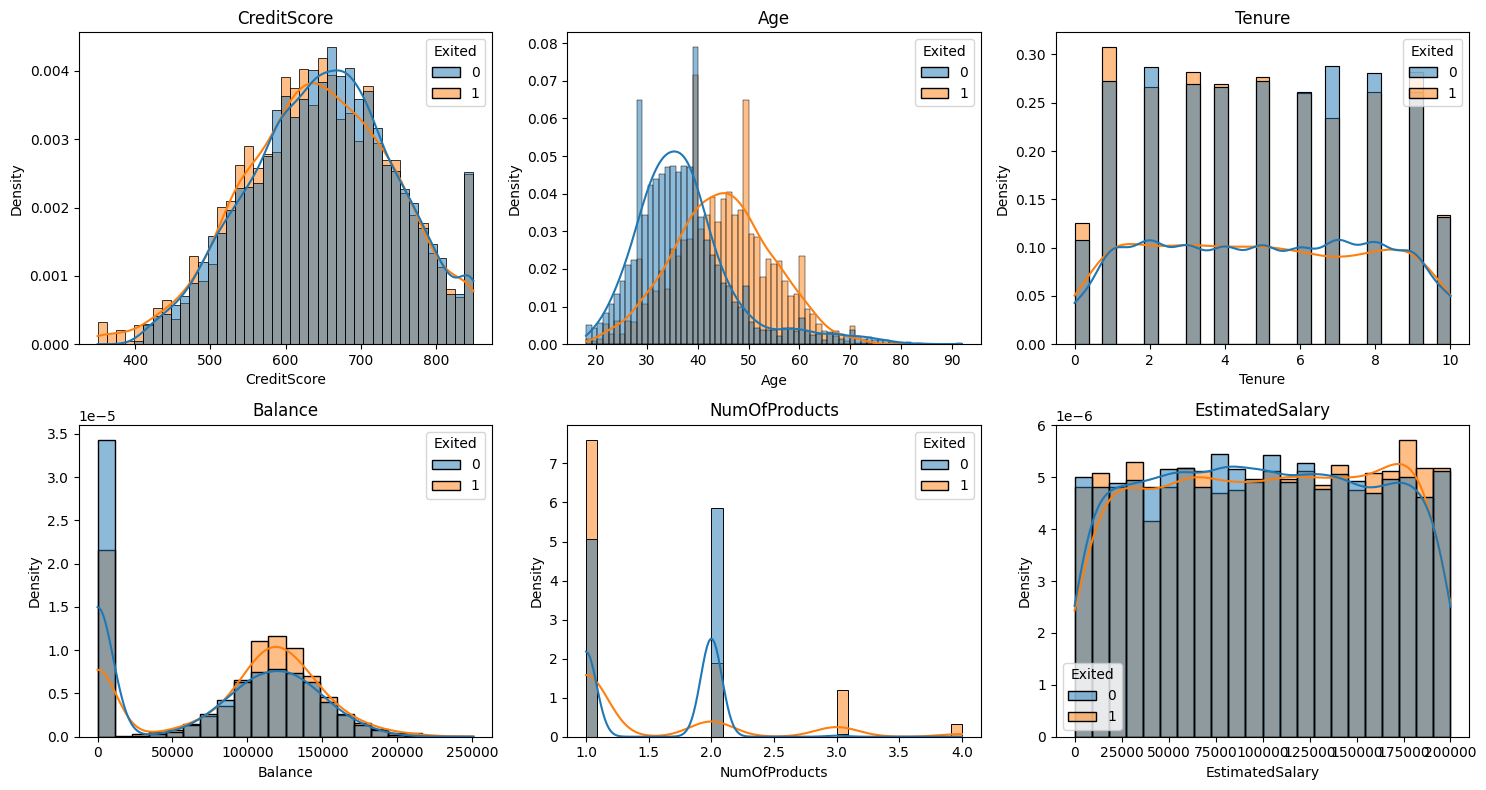

In [10]:
num_cols = ["CreditScore", "Age", "Tenure", "Balance", "NumOfProducts", "EstimatedSalary"]

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, col in zip(axes.ravel(), num_cols):
    sns.histplot(data=df, x=col, hue="Exited", kde=True, stat="density", common_norm=False, ax=ax)
    ax.set_title(col)
plt.tight_layout()
plt.show()

Para la matriz de correlación, las variables categóricas se codifican numéricamente y las numéricas se mantienen en su escala original.

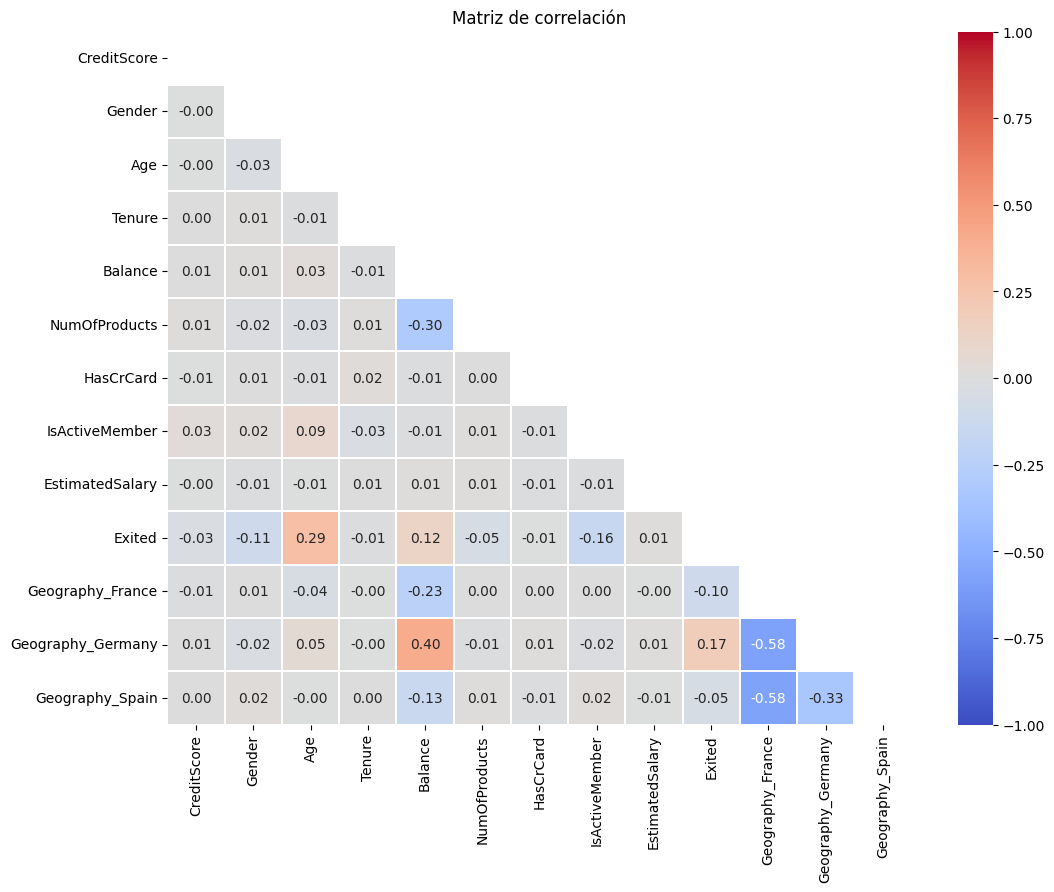

In [11]:
df_corr = df.copy()
df_corr["Gender"] = (df_corr["Gender"] == "Male").astype(int)
df_corr = pd.get_dummies(df_corr, columns=["Geography"], dtype=int)
corr = df_corr.corr()

plt.figure(figsize=(12, 9))
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, mask=mask, annot=True, fmt=".2f", linewidths=.2, cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Matriz de correlación")
plt.show()

## Paso 4: Codificación de variables

La codificación se define una sola vez a partir de los datos de entrenamiento y se reutiliza para cualquier cliente nuevo. Si se ajusta un `LabelEncoder` por separado sobre los clientes nuevos, las categorías reciben códigos distintos a los del entrenamiento y las predicciones dejan de ser válidas.

In [12]:
CATEGORICAS = ["Geography", "Gender"]
MAPEOS = {col: {v: i for i, v in enumerate(sorted(df[col].unique()))} for col in CATEGORICAS}
print(MAPEOS)

def codificar(data):
    data = data.copy()
    for col in CATEGORICAS:
        data[col] = data[col].map(MAPEOS[col])
    if data[CATEGORICAS].isnull().any().any():
        raise ValueError("Existen categorías no vistas en el entrenamiento.")
    return data

{'Geography': {'France': 0, 'Germany': 1, 'Spain': 2}, 'Gender': {'Female': 0, 'Male': 1}}


In [13]:
X = codificar(df.drop(columns="Exited"))
y = df["Exited"]
X.head()

,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary
0,619,0,0,42,2,0.000,1,1,1,101348.880
1,608,2,0,41,1,83807.860,1,0,1,112542.580
2,502,0,0,42,8,159660.800,3,1,0,113931.570
3,699,0,0,39,1,0.000,2,0,0,93826.630
4,850,2,0,43,2,125510.820,1,1,1,79084.100


## Paso 5: División de los datos

Se usan tres conjuntos estratificados: entrenamiento (60%), validación (20%) para el early stopping y prueba (20%) para la evaluación final.

In [14]:
X_temp, X_test, y_temp, y_test = train_test_split(X, y, test_size=0.20, stratify=y, random_state=SEED)
X_train, X_val, y_train, y_val = train_test_split(X_temp, y_temp, test_size=0.25, stratify=y_temp, random_state=SEED)

pd.DataFrame({"Observaciones": [len(y_train), len(y_val), len(y_test)],
              "Tasa de fuga": [y_train.mean(), y_val.mean(), y_test.mean()]},
             index=["Entrenamiento", "Validación", "Prueba"])

,Observaciones,Tasa de fuga
Entrenamiento,6000,0.204
Validación,2000,0.203
Prueba,2000,0.203


In [15]:
def evaluar(modelo, X_, y_, umbral=0.5):
    prob = modelo.predict_proba(X_)[:, 1]
    pred = (prob >= umbral).astype(int)
    return {"Accuracy": accuracy_score(y_, pred), "Precision": precision_score(y_, pred),
            "Recall": recall_score(y_, pred), "F1": f1_score(y_, pred), "AUC": roc_auc_score(y_, prob)}

def matriz_confusion(modelo, X_, y_, titulo, umbral=0.5):
    pred = (modelo.predict_proba(X_)[:, 1] >= umbral).astype(int)
    sns.heatmap(confusion_matrix(y_, pred), annot=True, fmt="d", cmap="Blues", linewidths=1, linecolor="black",
                xticklabels=["Permanece", "Abandona"], yticklabels=["Permanece", "Abandona"])
    plt.xlabel("Predicción")
    plt.ylabel("Valor real")
    plt.title(titulo)
    plt.show()

## Paso 6: Entrenar el modelo XGBoost

In [32]:
xgb_model = xgb.XGBClassifier(
    n_estimators=200,
    learning_rate=0.06,
    max_depth=4,
    min_child_weight=5,
    subsample=0.8,
    colsample_bytree=0.8,
    eval_metric="auc",
    early_stopping_rounds=50,
    random_state=SEED,
)
xgb_model.fit(X_train, y_train, eval_set=[(X_val, y_val)], verbose=False)
print("Número de árboles seleccionado:", xgb_model.best_iteration + 1)

Número de árboles seleccionado: 143


In [33]:
pd.DataFrame({"Entrenamiento": evaluar(xgb_model, X_train, y_train),
              "Prueba": evaluar(xgb_model, X_test, y_test)}).T

,Accuracy,Precision,Recall,F1,AUC
Entrenamiento,0.878,0.827,0.507,0.628,0.905
Prueba,0.869,0.798,0.477,0.597,0.863


In [18]:
print(classification_report(y_test, xgb_model.predict(X_test), target_names=["Permanece", "Abandona"]))

              precision    recall  f1-score   support

   Permanece       0.88      0.97      0.92      1593
    Abandona       0.81      0.47      0.59       407

    accuracy                           0.87      2000
   macro avg       0.84      0.72      0.76      2000
weighted avg       0.86      0.87      0.86      2000



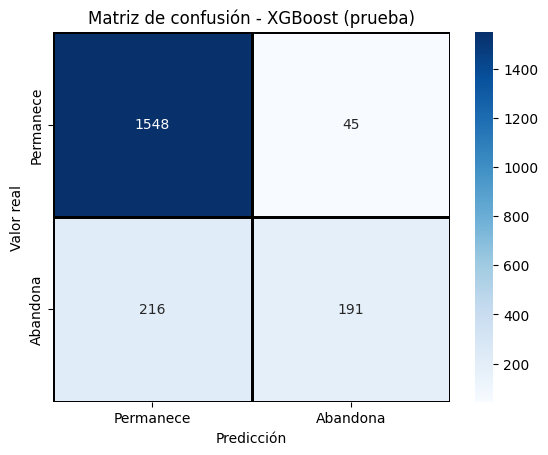

In [19]:
matriz_confusion(xgb_model, X_test, y_test, "Matriz de confusión - XGBoost (prueba)")

## Paso 7: Entrenar el modelo LightGBM

In [26]:
lgb_model = lgb.LGBMClassifier(
    n_estimators=200,
    learning_rate=0.06,
    num_leaves=15,
    min_child_samples=30,
    subsample=0.8,
    subsample_freq=1,
    colsample_bytree=0.8,
    random_state=SEED,
    verbose=-1,
)
lgb_model.fit(X_train, y_train, eval_set=[(X_val, y_val)], eval_metric="auc",
              categorical_feature=["Geography"], callbacks=[lgb.early_stopping(50, verbose=False)])
print("Número de árboles seleccionado:", lgb_model.best_iteration_)

Número de árboles seleccionado: 95


In [27]:
pd.DataFrame({"Entrenamiento": evaluar(lgb_model, X_train, y_train),
              "Prueba": evaluar(lgb_model, X_test, y_test)}).T

,Accuracy,Precision,Recall,F1,AUC
Entrenamiento,0.879,0.828,0.516,0.636,0.911
Prueba,0.868,0.784,0.482,0.597,0.864


In [34]:
print(classification_report(y_test, lgb_model.predict(X_test), target_names=["Permanece", "Abandona"]))

              precision    recall  f1-score   support

   Permanece       0.88      0.97      0.92      1593
    Abandona       0.78      0.48      0.60       407

    accuracy                           0.87      2000
   macro avg       0.83      0.72      0.76      2000
weighted avg       0.86      0.87      0.85      2000



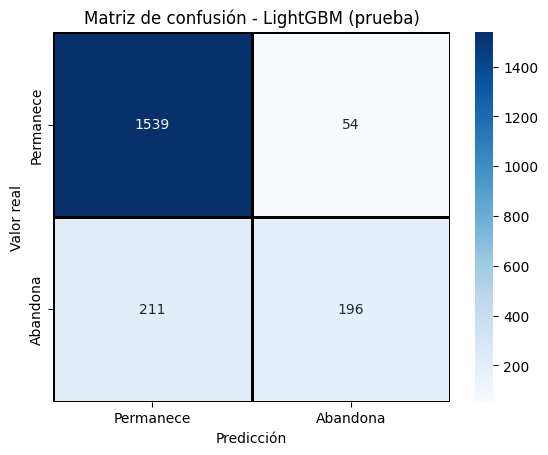

In [35]:
matriz_confusion(lgb_model, X_test, y_test, "Matriz de confusión - LightGBM (prueba)")

## Paso 8: Comparación de modelos

In [36]:
modelos = {"XGBoost": xgb_model, "LightGBM": lgb_model}
pd.DataFrame({nombre: evaluar(m, X_test, y_test) for nombre, m in modelos.items()}).T

,Accuracy,Precision,Recall,F1,AUC
XGBoost,0.869,0.798,0.477,0.597,0.863
LightGBM,0.868,0.784,0.482,0.597,0.864


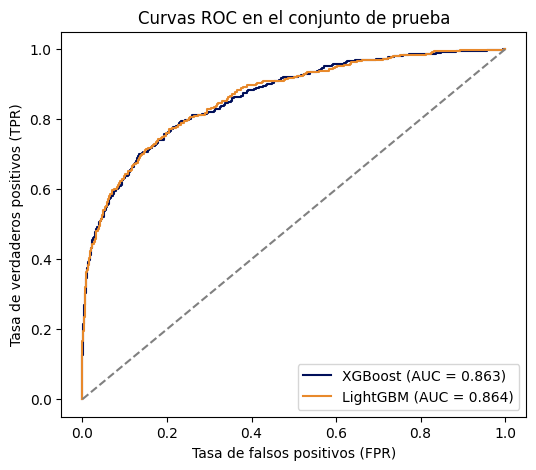

In [37]:
plt.figure(figsize=(6, 5))
for (nombre, modelo), color in zip(modelos.items(), ["#000F5A", "#E8892B"]):
    prob = modelo.predict_proba(X_test)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, prob)
    plt.plot(fpr, tpr, color=color, label=f"{nombre} (AUC = {roc_auc_score(y_test, prob):.3f})")
plt.plot([0, 1], [0, 1], linestyle="--", color="gray")
plt.xlabel("Tasa de falsos positivos (FPR)")
plt.ylabel("Tasa de verdaderos positivos (TPR)")
plt.title("Curvas ROC en el conjunto de prueba")
plt.legend()
plt.show()

## Paso 9: Ajuste del umbral de decisión

Con el umbral por defecto (0.5) el recall de la clase "Abandona" es bajo. Reducir el umbral permite identificar más clientes en riesgo a cambio de más falsos positivos. El umbral se elige con el conjunto de validación.

In [40]:
umbrales = [0.20, 0.25, 0.33, 0.35, 0.40, 0.45, 0.50]
pd.DataFrame({u: evaluar(lgb_model, X_val, y_val, umbral=u) for u in umbrales}).T.rename_axis("Umbral")

,Accuracy,Precision,Recall,F1,AUC
Umbral,,,,,
0.200,0.799,0.504,0.767,0.608,0.867
0.250,0.831,0.569,0.695,0.626,0.867
0.330,0.856,0.649,0.631,0.640,0.867
0.350,0.861,0.674,0.609,0.640,0.867
0.400,0.866,0.713,0.568,0.632,0.867
0.450,0.867,0.751,0.518,0.613,0.867
0.500,0.864,0.779,0.459,0.578,0.867


Desde el punto de vista del negocio, conviene contactar a un cliente si $p \cdot s \cdot V > C$, donde $p$ es la probabilidad de fuga, $s$ la tasa de éxito de la campaña, $V$ el valor del cliente y $C$ el costo de contacto. Los valores siguientes son supuestos ilustrativos.

In [39]:
V, C, s = 500, 50, 0.30
print(f"Umbral económico C/(s·V) = {C / (s * V):.2f}")

Umbral económico C/(s·V) = 0.33


In [41]:
UMBRAL = 0.35
pd.DataFrame({"Umbral 0.50": evaluar(lgb_model, X_test, y_test),
              f"Umbral {UMBRAL}": evaluar(lgb_model, X_test, y_test, umbral=UMBRAL)}).T

,Accuracy,Precision,Recall,F1,AUC
Umbral 0.50,0.868,0.784,0.482,0.597,0.864
Umbral 0.35,0.854,0.650,0.607,0.628,0.864


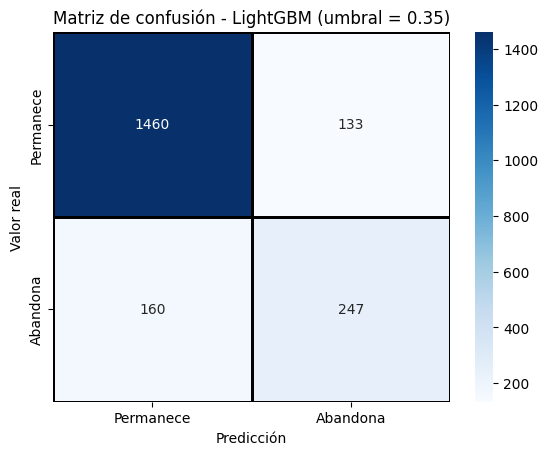

In [42]:
matriz_confusion(lgb_model, X_test, y_test, f"Matriz de confusión - LightGBM (umbral = {UMBRAL})", umbral=UMBRAL)

## Paso 10: Importancia de variables

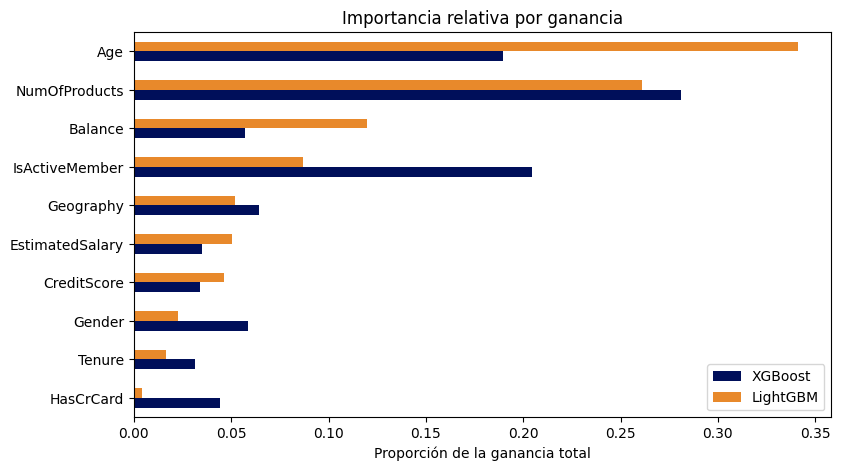

In [43]:
importancias = pd.DataFrame({
    "XGBoost": pd.Series(xgb_model.get_booster().get_score(importance_type="gain")),
    "LightGBM": pd.Series(lgb_model.booster_.feature_importance(importance_type="gain"),
                          index=lgb_model.booster_.feature_name()),
}).fillna(0)
importancias = (importancias / importancias.sum()).sort_values("LightGBM")

importancias.plot.barh(figsize=(9, 5), color=["#000F5A", "#E8892B"])
plt.title("Importancia relativa por ganancia")
plt.xlabel("Proporción de la ganancia total")
plt.show()

## Paso 11: Interpretación con SHAP

### 11.1 Qué mide SHAP

SHAP descompone la predicción de cada cliente en el aporte de cada variable. La descomposición es **aditiva**:

$$f(x) = E[f(X)] + \sum_{j=1}^{p} \phi_j$$

- $E[f(X)]$: valor base, es decir, la predicción promedio del modelo.
- $\phi_j$: aporte de la variable $j$ para ese cliente. Positivo empuja hacia la clase 1 (Abandona); negativo, hacia la clase 0 (Permanece).
- $f(x)$: predicción final para ese cliente.

La pregunta clave es **en qué escala está $f(x)$**. En XGBoost no es una probabilidad.

### 11.2 La escala de XGBoost: log-odds

XGBoost construye la predicción **sumando** las correcciones de cada árbol. Esa suma puede tomar cualquier valor real, por lo que no puede expresarse directamente como probabilidad (acotada entre 0 y 1). El modelo trabaja en **log-odds** y al final aplica la función sigmoide.

| Concepto | Fórmula | Rango |
|---|---|---|
| Probabilidad | $p$ | 0 a 1 |
| Odds | $\dfrac{p}{1-p}$ | 0 a $+\infty$ |
| Log-odds (logit) | $\ln\left(\dfrac{p}{1-p}\right)$ | $-\infty$ a $+\infty$ |
| Regreso a probabilidad (sigmoide) | $p = \dfrac{1}{1+e^{-f(x)}}$ | 0 a 1 |

Regla de lectura: log-odds negativo equivale a $p < 0.5$, cero a $p = 0.5$ y positivo a $p > 0.5$. Es la misma escala de la regresión logística.

In [44]:
def sigmoide(z):
    return 1 / (1 + np.exp(-z))

def logit(p):
    return np.log(p / (1 - p))

tasa = y_train.mean()
pd.DataFrame({"Valor": [tasa, tasa / (1 - tasa), logit(tasa)]},
             index=["Tasa de fuga (probabilidad)", "Odds", "Log-odds"])

,Valor
Tasa de fuga (probabilidad),0.204
Odds,0.256
Log-odds,-1.363


El valor base de SHAP **no es el promedio del target** (que solo toma 0 o 1), sino la **predicción esperada del modelo** expresada en log-odds. Por defecto, `TreeExplainer` la calcula con la información que los árboles guardaron durante el entrenamiento: cuántos datos pasaron por cada rama, ponderados en XGBoost por $p(1-p)$. El resultado queda muy cerca del logit de la tasa de fuga, aunque no es idéntico.

In [45]:
explainer = shap.TreeExplainer(xgb_model)
shap_values = explainer(X_test)

pd.DataFrame({"Log-odds": [logit(tasa), explainer.expected_value]},
             index=["Logit de la tasa de fuga", "Valor base de SHAP: E[f(X)]"]
            ).assign(Probabilidad=lambda d: sigmoide(d["Log-odds"]))

,Log-odds,Probabilidad
Logit de la tasa de fuga,-1.363,0.204
Valor base de SHAP: E[f(X)],-1.386,0.200


Una advertencia: **promediar log-odds no equivale a promediar probabilidades**. Los clientes de riesgo muy bajo tienen log-odds muy negativos (por ejemplo, −5) que arrastran el promedio hacia abajo, aunque en probabilidad casi no pesan (0.007). Por eso el promedio simple de las predicciones en log-odds no coincide con la tasa de fuga.

In [46]:
margen_train = xgb_model.predict(X_train, output_margin=True)
prob_train = xgb_model.predict_proba(X_train)[:, 1]

pd.DataFrame({"Log-odds": [margen_train.mean(), logit(prob_train.mean())],
              "Probabilidad": [sigmoide(margen_train.mean()), prob_train.mean()]},
             index=["Promedio de los log-odds", "Promedio de las probabilidades"])

,Log-odds,Probabilidad
Promedio de los log-odds,-1.917,0.128
Promedio de las probabilidades,-1.364,0.204


Comprobación de la aditividad para el primer cliente del conjunto de prueba: el valor base más la suma de los aportes reproduce exactamente la predicción del modelo.

In [50]:
X_test.head(3)

,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary
5702,585,0,1,36,7,0.000,2,1,0,94283.090
3667,525,1,1,33,4,131023.760,2,0,0,55072.930
1617,557,2,0,40,4,0.000,2,0,1,105433.530


In [54]:
i = 159
base = shap_values.base_values[i]
fx = base + shap_values.values[i].sum()

aportes = pd.DataFrame({"Valor del cliente": X_test.iloc[i],
                        "Aporte SHAP (log-odds)": shap_values.values[i]})
aportes = aportes.reindex(aportes["Aporte SHAP (log-odds)"].abs().sort_values(ascending=False).index)
display(aportes)

print(f"Valor base E[f(X)]      : {base:.3f}  ->  probabilidad {sigmoide(base):.3f}")
print(f"Suma de aportes         : {shap_values.values[i].sum():.3f}")
print(f"Predicción f(x)         : {fx:.3f}  ->  probabilidad {sigmoide(fx):.3f}")
print(f"predict_proba del modelo: {xgb_model.predict_proba(X_test.iloc[[i]])[0, 1]:.3f}")

,Valor del cliente,Aporte SHAP (log-odds)
Age,31.000,-0.977
IsActiveMember,1.000,-0.355
Geography,0.000,-0.276
Gender,0.000,0.199
NumOfProducts,1.000,0.180
Balance,140931.820,-0.104
HasCrCard,0.000,0.058
Tenure,7.000,-0.057
CreditScore,451.000,-0.031
EstimatedSalary,20388.770,-0.016


Valor base E[f(X)]      : -1.386  ->  probabilidad 0.200
Suma de aportes         : -1.379
Predicción f(x)         : -2.764  ->  probabilidad 0.059
predict_proba del modelo: 0.059


### 11.3 Importancia global

- **Gráfico de barras:** promedio del valor absoluto de SHAP por variable. Indica cuánto influye cada variable, sin dirección.
- **Beeswarm:** cada punto es un cliente. La posición horizontal es el aporte (en log-odds) y el color es el valor de la variable (rojo alto, azul bajo). Por ejemplo, si los puntos rojos de `Age` están a la derecha, edades altas aumentan el riesgo de fuga.

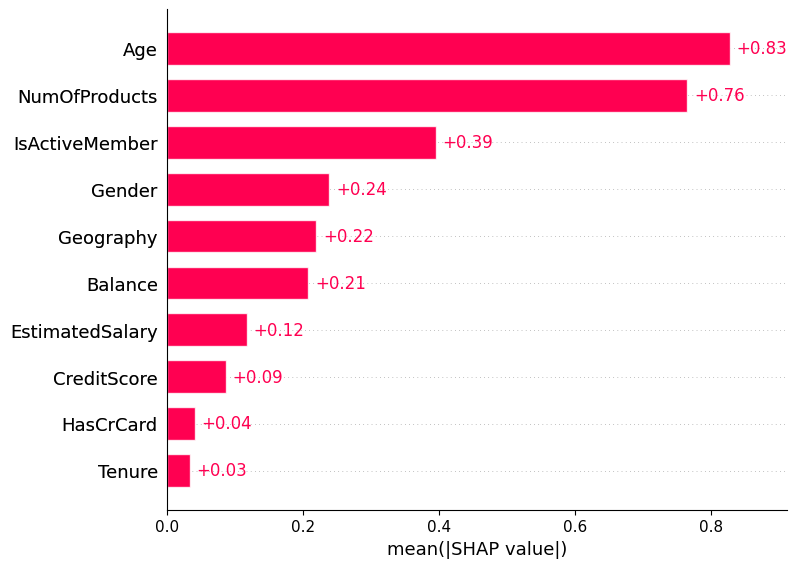

In [55]:
shap.plots.bar(shap_values, max_display=10)

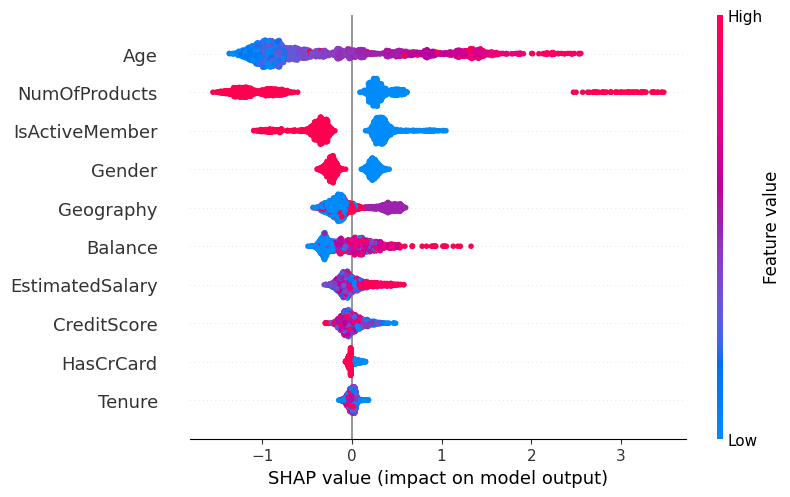

In [56]:
shap.plots.beeswarm(shap_values, max_display=10)

### 11.4 Explicación individual: gráfico waterfall

Se lee de abajo hacia arriba. Parte del valor base $E[f(X)]$, cada barra suma (rojo) o resta (azul) log-odds, y termina en la predicción $f(x)$ del cliente. A la izquierda se muestra el valor de cada variable para ese cliente, con la codificación del Paso 4 (por ejemplo, `Geography = 0` es France y `Gender = 1` es Male).

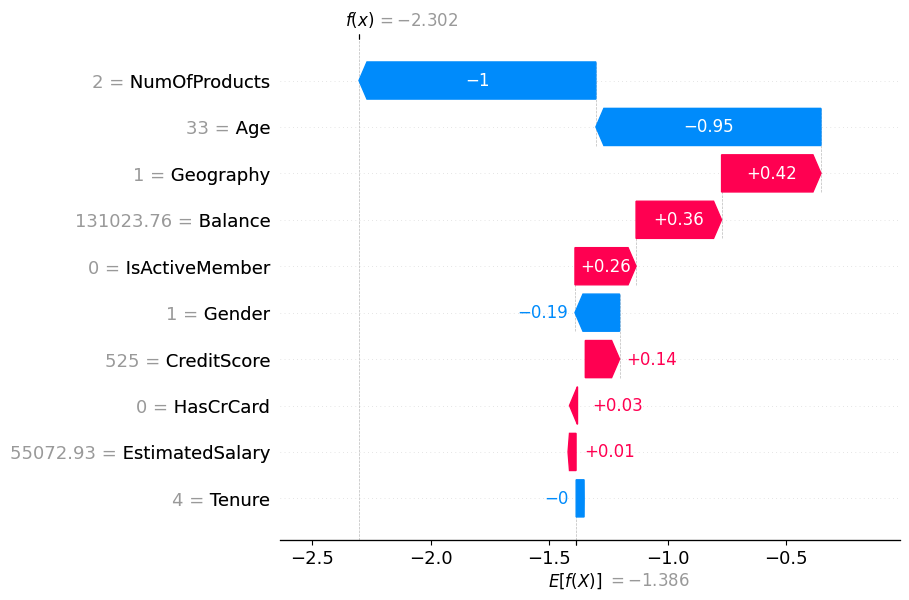

In [58]:
shap.plots.waterfall(shap_values[1])

### 11.5 SHAP en escala de probabilidad

Para comunicar resultados al negocio puede ser más intuitivo expresar los aportes en probabilidad. Se indica `model_output="probability"` y una muestra de referencia; en este caso, el valor base es exactamente el promedio de las probabilidades predichas sobre esa muestra. Los aportes siguen sumando exactamente la predicción, pero ahora en puntos de probabilidad. Como la sigmoide no es lineal, estos aportes no son una simple conversión de los aportes en log-odds.

Valor base (probabilidad): 0.170
Promedio de probabilidades en la muestra de referencia: 0.169


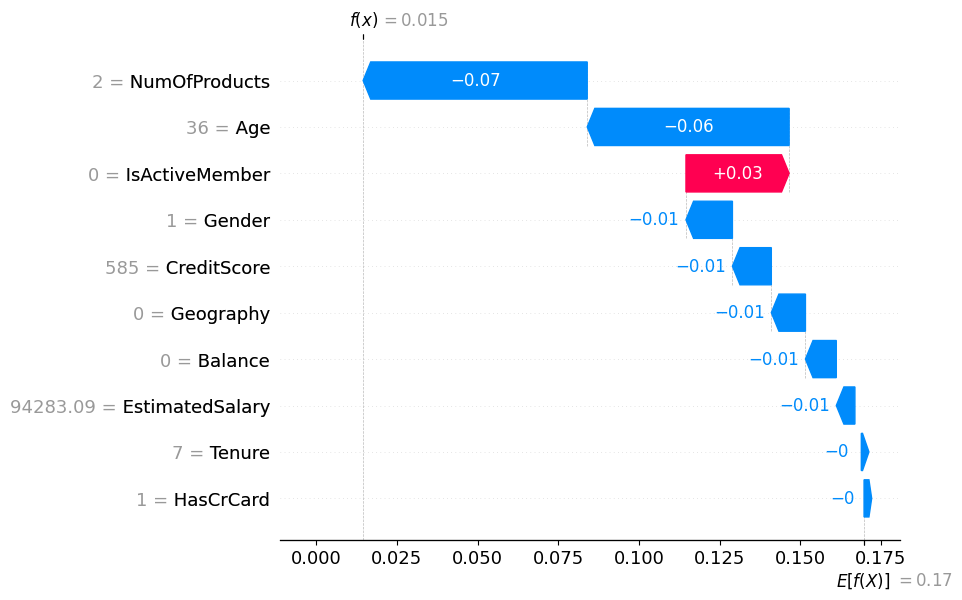

In [60]:
fondo = X_train.sample(200, random_state=SEED)
# Usamos el explicador genérico de SHAP pasándole la función de predicción de probabilidad directa del modelo
explainer_prob = shap.Explainer(xgb_model.predict_proba, fondo)
shap_prob = explainer_prob(X_test.iloc[[0]])

# Seleccionamos el índice 1 para ver el aporte hacia la clase 'Abandona' (clase positiva)
print(f"Valor base (probabilidad): {shap_prob.base_values[0, 1]:.3f}")
print(f"Promedio de probabilidades en la muestra de referencia: {xgb_model.predict_proba(fondo)[:, 1].mean():.3f}")
shap.plots.waterfall(shap_prob[0, :, 1])

### 11.6 Comparación con Random Forest

En Random Forest cada árbol devuelve una proporción de la clase 1 en su hoja (ya es una probabilidad) y el bosque **promedia** esas proporciones. Un promedio de valores entre 0 y 1 permanece entre 0 y 1, por lo que SHAP trabaja directamente en probabilidad.

| | Random Forest | XGBoost / LightGBM |
|---|---|---|
| Combinación de árboles | Promedio (bagging) | Suma de correcciones (boosting) |
| Salida de cada árbol | Probabilidad | Ajuste en log-odds |
| Escala de SHAP por defecto | Probabilidad | Log-odds |
| Valor base en este caso | ≈ 0.20 | ≈ −1.4 |

Además, para Random Forest SHAP devuelve aportes para ambas clases (son simétricos), por lo que se selecciona la clase 1.

Dimensiones (clientes, variables, clases): (2, 10, 2)
Valor base clase 1: 0.204 (probabilidad)


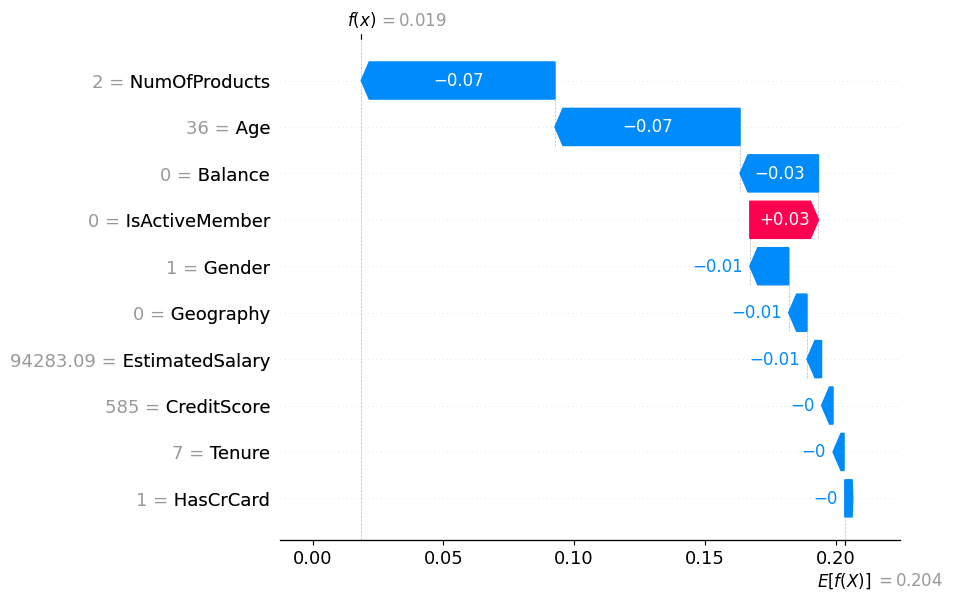

In [62]:
from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(n_estimators=200, min_samples_leaf=10, n_jobs=-1, random_state=SEED)
rf_model.fit(X_train, y_train)

shap_rf = shap.TreeExplainer(rf_model)(X_test.iloc[:2])
print("Dimensiones (clientes, variables, clases):", shap_rf.values.shape)
print(f"Valor base clase 1: {shap_rf.base_values[0, 1]:.3f} (probabilidad)")
shap.plots.waterfall(shap_rf[0, :, 1])

## Paso 12: Predicción para nuevos clientes

In [63]:
nuevos_clientes = pd.DataFrame([
    {"CreditScore": 580, "Geography": "Germany", "Gender": "Male", "Age": 52, "Tenure": 2,
     "Balance": 0.0, "NumOfProducts": 1, "HasCrCard": 0, "IsActiveMember": 0, "EstimatedSalary": 45000.0},
    {"CreditScore": 710, "Geography": "Spain", "Gender": "Female", "Age": 30, "Tenure": 8,
     "Balance": 120000.0, "NumOfProducts": 2, "HasCrCard": 1, "IsActiveMember": 1, "EstimatedSalary": 95000.0},
], index=["Cliente 1", "Cliente 2"])

X_nuevos = codificar(nuevos_clientes)[X.columns]
X_nuevos

,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary
Cliente 1,580,1,1,52,2,0.000,1,0,0,45000.000
Cliente 2,710,2,0,30,8,120000.000,2,1,1,95000.000


In [64]:
resultado = nuevos_clientes[["Geography", "Gender", "Age", "IsActiveMember"]].copy()
for nombre, modelo in modelos.items():
    resultado[f"Prob. fuga {nombre}"] = modelo.predict_proba(X_nuevos)[:, 1]
resultado["Predicción"] = (resultado["Prob. fuga LightGBM"] >= UMBRAL).astype(int)
resultado

,Geography,Gender,Age,IsActiveMember,Prob. fuga XGBoost,Prob. fuga LightGBM,Predicción
Cliente 1,Germany,Male,52,0,0.831,0.804,1
Cliente 2,Spain,Female,30,1,0.056,0.058,0


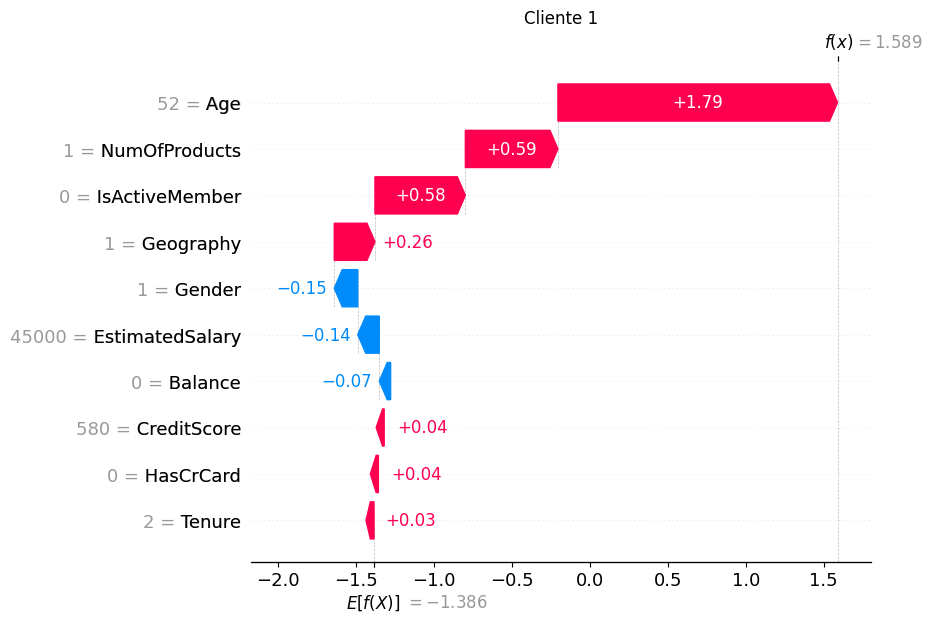

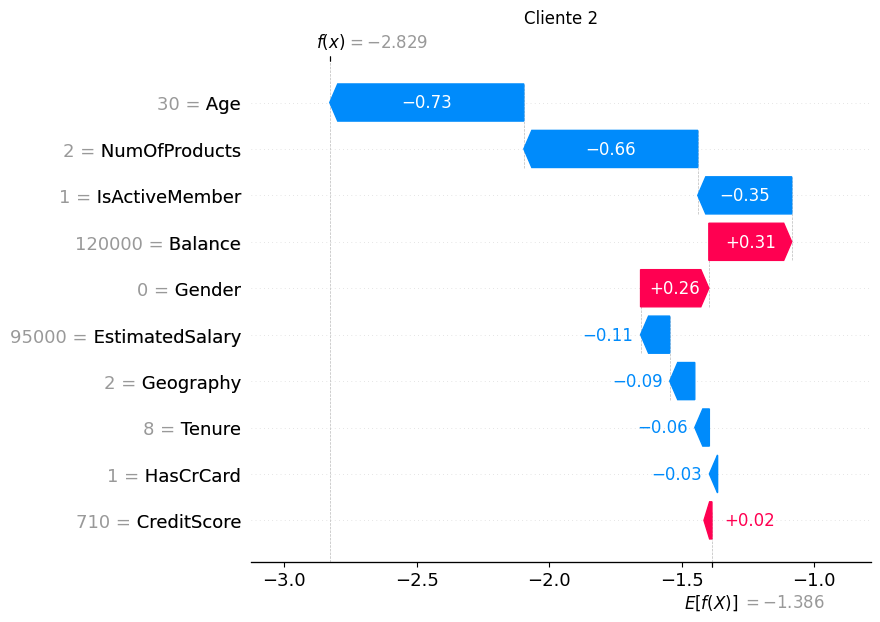

In [65]:
shap_nuevos = explainer(X_nuevos)
for i, nombre in enumerate(X_nuevos.index):
    shap.plots.waterfall(shap_nuevos[i], show=False)
    plt.title(nombre)
    plt.show()